# Machine Learning Study - Learning Different Models 

## Basics 

In this notebook we will cover the fundamental machine learning models:
- Linear Regression
- Logistic Regression
- k-means
- k-nearest neighbors
- decision tree (Gini or entropy)
- 2 layer Neural Networks (NN)
    - with backpropogation

For each model we cover:
1. What is the objective of the the model and what is the learning procedure?
2. What does it assume about the data?
3. What are the main 2-3 hyperparameters?
4. How useful is it under class imbalance?
5. What does inference cost, and how would you serve and monitor it?

#### **Data Disclaimer**

For each model we will use base dataset provided by scikit-learn(sklearn) and seaborn (sns). If a custom dataset is used, it will be noted as such. Links and references will be provided.

#### **Base Imports**

Import the data, numerical, and plotting libraries you used in the previous notebooks. All code cells in this notebook are intentionally blank for you to implement.


In [1]:
import pandas as pd
import numpy as np
import sklearn
import seaborn as sns
import plotly as px
import matplotlib.pyplot as plt

### **3. k-Nearest Neighbors (k-NN)**

k-NN predicts an outcome using the training examples closest to a new input. It can do **classification** (vote for a class) or **regression** (average target values). Here we use **classification** to predict malignant or benign tumors.

For a new input $x$, let $N_k(x)$ be the indices of its $k$ nearest training examples. With uniform voting:

$$\hat{y}(x) = \underset{c}{\operatorname{argmax}}\sum_{i\in N_k(x)}\mathbf{1}(y_i=c)$$

For example, with $k=5$, if 4 neighbors are malignant and 1 is benign, the prediction is malignant. Its estimated malignant probability is $4/5=0.8$ with uniform weights. This is a neighbor vote fraction, not a guarantee of calibrated confidence.

For k-NN:
1. **Objective and learning procedure:** predict using nearby labeled examples. Fitting stores the training data and may build a search structure; it does not learn coefficients by minimizing a loss through gradient descent. At prediction time it finds neighbors and combines their labels. We choose hyperparameters using validation scores.

2. **Assumptions:** nearby examples should tend to have similar labels, and the chosen distance should reflect meaningful similarity. Features must be represented numerically. Feature scaling matters because large numerical ranges can dominate distances. Irrelevant features and high dimensionality can make neighborhoods less informative. It does not require a linear decision boundary.

3. **Main hyperparameters:**
    - `n_neighbors`: the number $k$ of neighbors. Small $k$ can fit noise; large $k$ smooths predictions and may miss local structure.
    - `weights`: uniform voting or distance weighting, where closer neighbors contribute more.
    - `p`: with Minkowski distance, $p=1$ gives Manhattan distance and $p=2$ gives Euclidean distance.

4. **Class imbalance:** majority-class examples can dominate neighborhoods, so accuracy alone can be misleading. Check precision, recall, F1, and the confusion matrix. Distance weighting may help in some neighborhoods, but does not directly rebalance classes. Unlike logistic regression, `KNeighborsClassifier` has no `class_weight` parameter.

5. **Inference and deployment:** brute-force distance computation costs roughly $O(nd)$ per query for $n$ training rows and $d$ features, plus neighbor selection. Search structures may help, depending on the data and dimensionality. The model retains training examples, requiring roughly $O(nd)$ storage. Save the scaler and classifier together in a pipeline. Monitor feature drift, prediction quality when labels arrive, memory, and prediction latency.


#### **Distance and Neighbor Voting**

Euclidean distance between inputs $x$ and $z$ with $d$ features is:

$$D(x,z) = \sqrt{\sum_{j=1}^{d}(x_j-z_j)^2}$$

Before using the full dataset, build a small two-feature demonstration:

- Plot labeled training points and one new query point.
- Highlight the query's nearest neighbors and show their class vote.
- Try $k=1$, $k=3$, and $k=5$, then compare uniform and distance-weighted voting.
- Change one feature's scale and inspect how the selected neighbors change.

Optionally add a slider for $k$, like the sigmoid controls in the logistic regression notebook. Implement the demonstration in the blank cell below.


#### **Data Set for k-Nearest Neighbors**

Use the same sklearn [Breast Cancer dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html) as the logistic regression notebook. Predict malignant or benign tumors from 30 numeric measurements.

Sklearn labels malignant as **0** and benign as **1**. Flip the target so **malignant = 1** (the positive class), matching your previous notebook.

In the first cell, load the dataset, create the target, and inspect the shape and class counts. In the second, plot mean radius against mean texture, colored by class.


In [2]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer(as_frame=True)
cancer = data.frame.assign(malignant = (data.target == 0).astype(int)).drop(columns='target')
print(cancer.shape)
cancer['malignant'].value_counts()

(569, 31)


malignant
0    357
1    212
Name: count, dtype: int64

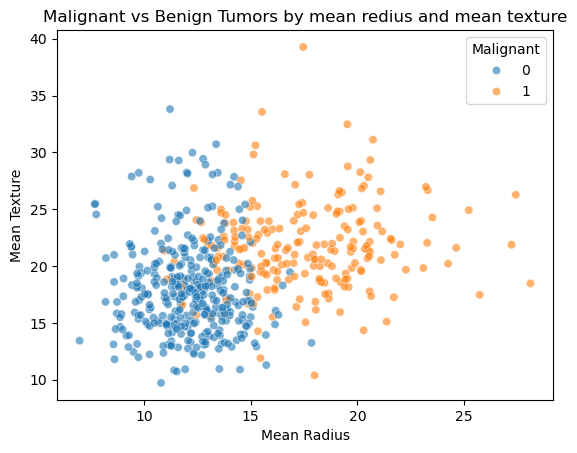

In [3]:
sns.scatterplot(data=cancer, x='mean radius', y='mean texture', hue='malignant', alpha=0.6)
plt.title('Malignant vs Benign Tumors by mean redius and mean texture')
plt.xlabel('Mean Radius')
plt.ylabel('Mean Texture')
plt.legend(title="Malignant")
plt.show()


#### **Splitting the data and modeling**

Use the same features, target, and split settings as logistic regression: 30% test data, `random_state=42`, and stratification by the target.

Build a pipeline with `StandardScaler` followed by `KNeighborsClassifier`. Start with 5 neighbors, uniform weights, and Euclidean distance. Fit on the training data, predict the test labels, and report accuracy, precision, recall, and F1.

The scaler must learn its statistics from training data only. Keep it inside the pipeline so cross-validation also fits scaling separately within each training fold.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

features = data.feature_names
X = np.array(cancer[features])
y = np.array(cancer['malignant'])

X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42, stratify=y)

model = make_pipeline(StandardScaler(), KNeighborsClassifier())
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(f'Accuracy: {accuracy_score(y_test, y_pred):.4f}')
print(f'Percision: {precision_score(y_test, y_pred):.4f}')
print(f'Recall: {recall_score(y_test, y_pred):.4f}')
print(f'F1: {f1_score(y_test, y_pred):.4f}')

from sklearn.metrics import roc_auc_score
print(f'ROC-AUC: {roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]):.4f}')


Accuracy: 0.9649
Percision: 1.0000
Recall: 0.9062
F1: 0.9508
ROC-AUC: 0.9882


#### **Evaluating the model**

Accuracy on its own does not tell us much. We check:
1. **Neighbors:** inspect a prediction's nearest training examples, their distances, and their labels. k-NN has no learned coefficients or intercept.
2. **Baseline:** does the model beat always predicting the majority class?
3. **Train vs test:** a big gap can indicate overfitting. Training predictions can look especially strong because a training point can be its own neighbor.
4. **Cross-validation:** is the score stable across training-data folds? Use the full scaling pipeline and keep the test set reserved for final evaluation.
5. **Confusion matrix:** how many malignant tumors are missed, and how many benign tumors are flagged?
6. **Worst predictions:** where is it confidently wrong? Inspect class vote fractions from `predict_proba` and the corresponding neighborhoods.

Use the first cell for neighbor inspection, a `DummyClassifier` baseline, a train/test metric table, and cross-validation on the training data. Use the second for the confusion matrix and the most confident incorrect predictions. If inspecting neighbors through the fitted classifier, transform the query with the fitted pipeline scaler first.


In [5]:
from IPython.display import display
from sklearn.dummy import DummyClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 1. Inspect neighbors in the same scaled space used for predictions.
def neighbor_table(test_position):
    query = model[0].transform(X_test[[test_position]])
    distances, positions = model[-1].kneighbors(query)
    return pd.DataFrame({
        'train_position': positions[0],
        'distance': distances[0],
        'malignant': y_train[positions[0]],
    })


print(f'Test example 0: actual={y_test[0]}, predicted={model.predict(X_test[[0]])[0]}')
neighbors = neighbor_table(0)
display(neighbors.round(4))
print(f"Malignant votes: {neighbors['malignant'].sum()} / {len(neighbors)}\n")

# 2. Baseline: always predict the majority class.
baseline = DummyClassifier(strategy='most_frequent').fit(X_train, y_train)


def knn_scores(estimator, X_eval, y_eval):
    predictions = estimator.predict(X_eval)
    malignant_column = np.flatnonzero(estimator.classes_ == 1)[0]
    probabilities = estimator.predict_proba(X_eval)[:, malignant_column]
    return {
        'Accuracy': accuracy_score(y_eval, predictions),
        'Precision': precision_score(y_eval, predictions, zero_division=0),
        'Recall': recall_score(y_eval, predictions, zero_division=0),
        'F1': f1_score(y_eval, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_eval, probabilities),
    }


# 3. Compare baseline, training, and held-out test performance.
report = pd.DataFrame({
    'baseline (test)': knn_scores(baseline, X_test, y_test),
    'model (train)': knn_scores(model, X_train, y_train),
    'model (test)': knn_scores(model, X_test, y_test),
})
display(report.round(4))

# 4. Cross-validation refits the entire pipeline within each training fold.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_recall = cross_val_score(model, X_train, y_train, cv=cv, scoring='recall')
print(f'5-fold training CV recall: {cv_recall.mean():.4f} ± {cv_recall.std():.4f}')
print('Fold recalls:', np.round(cv_recall, 4))


Test example 0: actual=0, predicted=0


,train_position,distance,malignant
0,349,1.6357,1
1,9,1.8340,0
2,396,1.9777,0
3,254,2.1519,0
4,369,2.1844,0


Malignant votes: 1 / 5



,baseline (test),model (train),model (test)
Accuracy,0.6257,0.9724,0.9649
Precision,0.0000,0.9928,1.0000
Recall,0.0000,0.9324,0.9062
F1,0.0000,0.9617,0.9508
ROC-AUC,0.5000,0.9975,0.9882


5-fold training CV recall: 0.9046 ± 0.0515
Fold recalls: [0.9333 0.9667 0.9333 0.8276 0.8621]


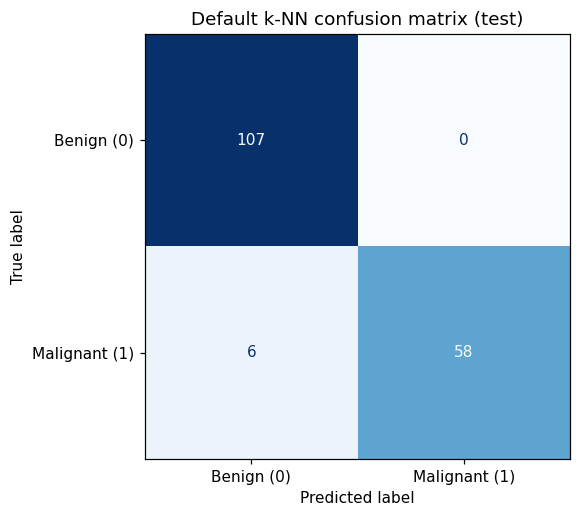

Incorrect test predictions: 6 / 171


,test_position,actual,predicted,p_malignant,predicted_vote_fraction
148,148,1,0,0.0,1.0
21,21,1,0,0.2,0.8
125,125,1,0,0.2,0.8
159,159,1,0,0.2,0.8
168,168,1,0,0.2,0.8


Neighbors of the most confident error (test position 148):


,train_position,distance,malignant
0,171,1.9400,0
1,100,2.0326,0
2,255,2.1877,0
3,355,2.2184,0
4,38,2.5268,0


In [6]:
from sklearn.metrics import ConfusionMatrixDisplay

# 5. Rows are actual labels; columns are predictions. Malignant = 1.
y_pred = model.predict(X_test)
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, labels=[0, 1],
    display_labels=['Benign (0)', 'Malignant (1)'],
    cmap='Blues', colorbar=False,
)
plt.title('Default k-NN confusion matrix (test)')
plt.tight_layout()
plt.show()

# 6. Rank incorrect predictions by the fraction voting for the predicted class.
malignant_column = np.flatnonzero(model.classes_ == 1)[0]
proba = model.predict_proba(X_test)[:, malignant_column]
errors = pd.DataFrame({
    'test_position': np.arange(len(y_test)),
    'actual': y_test,
    'predicted': y_pred,
    'p_malignant': proba,
    'predicted_vote_fraction': np.where(y_pred == 1, proba, 1 - proba),
})
wrong = errors[errors['actual'] != errors['predicted']]
worst = wrong.sort_values('predicted_vote_fraction', ascending=False).head(5)
print(f'Incorrect test predictions: {len(wrong)} / {len(y_test)}')
display(worst.round(4))

if not worst.empty:
    worst_position = int(worst.iloc[0]['test_position'])
    print(f'Neighbors of the most confident error (test position {worst_position}):')
    display(neighbor_table(worst_position).round(4))


### Personal Learning

Terminology:
- **Neighbor:** a stored training example close to a query under the chosen distance.
- **$k$:** the number of neighbors consulted; a hyperparameter you choose, not a coefficient learned during fitting.
- **Uniform voting:** each selected neighbor contributes one vote.
- **Distance weighting:** closer neighbors contribute more to the prediction.
- **Standardization:** $x_j'=(x_j-\mu_j)/s_j$, using the training mean and standard deviation for each feature.
- **Curse of dimensionality:** with many features, neighborhoods can become sparse and distances less useful for identifying similar examples.

Classification metrics (malignant = positive):
- **TP:** predicted malignant, actually malignant.
- **FP:** predicted malignant, actually benign.
- **FN:** predicted benign, actually malignant.
- **TN:** predicted benign, actually benign.
- **Accuracy:** $(TP+TN)/(TP+TN+FP+FN)$.
- **Precision:** $TP/(TP+FP)$; how many predicted malignant tumors are malignant?
- **Recall:** $TP/(TP+FN)$; how many malignant tumors do we catch?
- **F1:** $2PR/(P+R)$; balances precision and recall.

Model behavior:
- Small $k$ gives flexible boundaries and can be sensitive to noise.
- Large $k$ gives smoother boundaries and can underfit or favor the majority class.
- Odd $k$ avoids equal class vote counts in binary classification with uniform weights, but distance ties can still occur.
- `predict_proba` uses class vote fractions (weighted fractions with distance weighting). Inspect `classes_` to identify the malignant probability column.
- A vote fraction of 1 does not prove the model is correct; all selected neighbors can agree and still be misleading.

Stratify and pipelines:
- `stratify=y` preserves approximately the class ratio in each split; it does not balance the classes.
- The pipeline learns scaling from training data and reuses it at prediction time.
- Cross-validation must include preprocessing inside the pipeline to prevent leakage between folds.

Your observations:
- How did k-NN compare with logistic regression on the same split?
- Which mistakes changed as you adjusted $k$?
- Did scaling change the selected neighbors?
- What did inspecting a confidently wrong neighborhood reveal?


### **Room for optimization?**

Tune `n_neighbors`, `weights`, and `p` with `GridSearchCV` on the training data, keeping scaling inside the pipeline. Try neighbor counts such as 3, 5, 7, 11, and 15; uniform and distance weights; and Manhattan versus Euclidean distance.

For continuity with your logistic regression experiment, tune for **recall** and keep an eye on precision. Compare the default and tuned models using the same held-out test split once the configuration is selected. Do not use test scores to choose further hyperparameters.

If investigating a different probability threshold, select it using validation data or out-of-fold training predictions before evaluating it on the test set.


In [7]:
from sklearn.model_selection import GridSearchCV

# Tune on training data only, using the same folds as the default-model check.
grid = GridSearchCV(
    make_pipeline(StandardScaler(), KNeighborsClassifier()),
    param_grid={
        'kneighborsclassifier__n_neighbors': [3, 5, 7, 11, 15],
        'kneighborsclassifier__weights': ['uniform', 'distance'],
        'kneighborsclassifier__p': [1, 2],
    },
    scoring='recall',
    cv=cv,
)
grid.fit(X_train, y_train)
tuned_model = grid.best_estimator_
print(f'Best parameters: {grid.best_params_}')
print(f'Default 5-fold CV recall: {cv_recall.mean():.4f}')
print(f'Best 5-fold CV recall: {grid.best_score_:.4f}')

# Compare on the held-out test set after selecting the configuration.
comparison = pd.DataFrame({
    'Default (5 neighbors)': knn_scores(model, X_test, y_test),
    'Tuned (GridSearchCV)': knn_scores(tuned_model, X_test, y_test),
}).T
display(comparison.round(4))


Best parameters: {'kneighborsclassifier__n_neighbors': 7, 'kneighborsclassifier__p': 2, 'kneighborsclassifier__weights': 'uniform'}
Default 5-fold CV recall: 0.9046
Best 5-fold CV recall: 0.9251


,Accuracy,Precision,Recall,F1,ROC-AUC
Default (5 neighbors),0.9649,1.0,0.9062,0.9508,0.9882
Tuned (GridSearchCV),0.9649,1.0,0.9062,0.9508,0.9871


#### **Takeaways**

- **The default model beats the baseline.** Always predicting benign gives 62.57% test accuracy and 0% malignant recall. Default k-NN gives 96.49% accuracy, 100% precision, 90.62% recall, and an F1 score of 95.08%. It catches 58 of 64 malignant cases, misses 6, and incorrectly flags no benign cases.

- **There is no large train/test gap, but recall varies across folds.** Training accuracy is 97.24% versus 96.49% on the test set; training recall is 93.24% versus 90.62%. This does not suggest severe overfitting on this split, although training scores benefit from examples being their own neighbors. Default five-fold training CV recall is 90.46% ± 5.15 percentage points (standard deviation across folds), so performance depends somewhat on which examples are held out.

- **Unanimous neighbors can still be wrong.** The most confident error is a malignant test example whose five nearest training examples are all benign. Its malignant vote fraction is 0, yet the prediction is incorrect. Neighbor agreement is not a guarantee of correctness or calibrated confidence.

- **Tuning improved the selection score, but not held-out performance.** GridSearchCV tried 20 combinations and selected 7 neighbors, uniform voting, and Euclidean distance (`p=2`). Its mean training CV recall was 92.51%, compared with 90.46% for the default. Two individual test predictions changed, but test accuracy, precision, recall, and F1 stayed the same, while ROC-AUC changed slightly from 0.9882 to 0.9871. This experiment gives no evidence of a test-set improvement from tuning.

- **Logistic regression performed better at catching malignant cases on this split.** On the same features and split, the default logistic regression model has 93.75% recall and 96.00% F1, compared with 90.62% recall and 95.08% F1 for k-NN. Logistic regression catches two more malignant cases, with one benign false alarm instead of zero. This is a comparison on one dataset and split, not a general ranking of the models.

- **Next steps:** inspect the neighborhoods of missed malignant cases and investigate feature selection or a different decision threshold using training-data validation. Keep scaling inside the pipeline. We did not compare scaled and unscaled models, so this experiment does not measure the effect of scaling. Because these test results have already been inspected, use fresh held-out data for an unbiased final assessment after further changes.


### End of File
